In [1]:
!pip install deepface

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.5/169.5 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 197.1/197.1 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.4/59.4 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 40.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 2.7 MB/s eta 0:00:00


Detected Emotion: happy


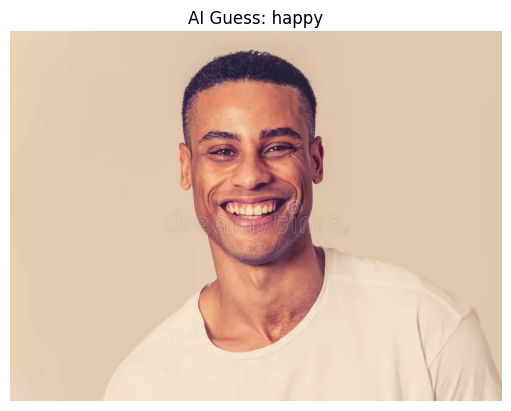

In [23]:
from deepface import DeepFace
import cv2
import matplotlib.pyplot as plt

#  PICK AN IMAGE ---
# Change this to any image path in your Drive
img_path = "/content/happy_image.jpg"

# ANALYZE ---
# This automatically detects the face and the emotion
results = DeepFace.analyze(img_path = img_path, actions = ['emotion'])

# SHOW RESULTS ---
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print(f"Detected Emotion: {results[0]['dominant_emotion']}")
plt.imshow(img)
plt.title(f"AI Guess: {results[0]['dominant_emotion']}")
plt.axis('off')
plt.show()

In [11]:
import os
import pandas as pd

#  Point to your folder
folder_path = "/content/drive/MyDrive/emotion_dataset"
all_results = []

# Loop through every file
for filename in os.listdir(folder_path):
    if filename.endswith(".jpg") or filename.endswith(".png"):
        path = os.path.join(folder_path, filename)
        try:
            # Analyze
            res = DeepFace.analyze(img_path = path, actions = ['emotion'], enforce_detection=False)

            # Store the name and the result
            all_results.append({
                "Filename": filename,
                "Emotion": res[0]['dominant_emotion'],
                "Confidence": res[0]['emotion'][res[0]['dominant_emotion']]
            })
            print(f"Finished: {filename}")
        except:
            print(f"Skipped: {filename} (No face found)")


In [13]:
from deepface import DeepFace
import os

folder_path = "/content/drive/MyDrive/emotion_dataset/test"

all_results = []

for emotion_label in os.listdir(folder_path):
    emotion_folder = os.path.join(folder_path, emotion_label)

    if os.path.isdir(emotion_folder):
        for filename in os.listdir(emotion_folder):
            if filename.lower().endswith(('.jpg', '.png')):

                path = os.path.join(emotion_folder, filename)

                try:
                    res = DeepFace.analyze(
                        img_path=path,
                        actions=['emotion'],
                        enforce_detection=False
                    )

                    all_results.append({
                        "Filename": filename,
                        "Actual": emotion_label.lower(),  # ✅ from folder
                        "Predicted": res[0]['dominant_emotion'].lower()
                    })

                except:
                    print("Skipped:", filename)

print("Total processed:", len(all_results))

Skipped: PrivateTest_42787778.jpg
Total processed: 7177


In [14]:
import pandas as pd

df = pd.DataFrame(all_results)

# 🔍 Check data first
print(df.head())
print(df.columns)

                   Filename   Actual Predicted
0  PrivateTest_47752858.jpg  neutral       sad
1  PrivateTest_49985410.jpg  neutral   neutral
2  PrivateTest_45065652.jpg  neutral   neutral
3  PrivateTest_46022583.jpg  neutral   neutral
4  PrivateTest_45151908.jpg  neutral   neutral
Index(['Filename', 'Actual', 'Predicted'], dtype='object')


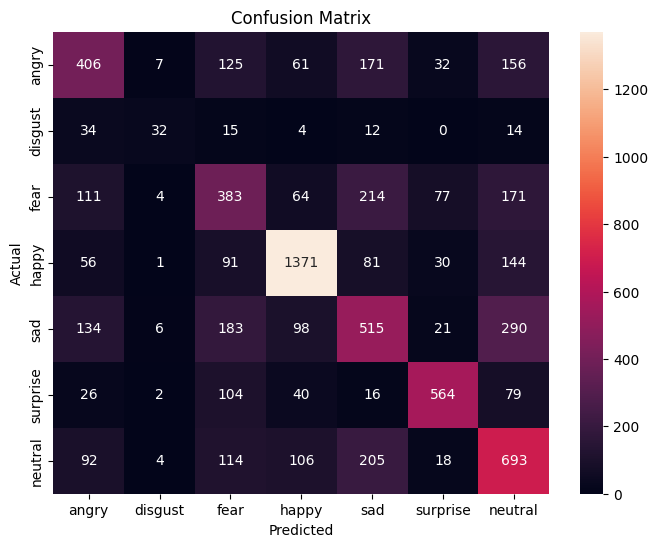

In [16]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ['angry','disgust','fear','happy','sad','surprise','neutral']

cm = confusion_matrix(df['Actual'], df['Predicted'], labels=labels)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

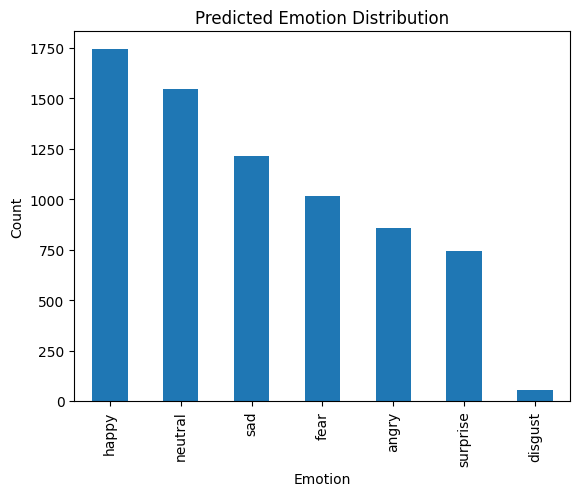

In [18]:
# bar graph emotion distribution
df['Predicted'].value_counts().plot(kind='bar')
plt.title("Predicted Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.show()

In [19]:
accuracy = (df['Actual'] == df['Predicted']).mean() * 100
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 55.23%


In [20]:
# classification report
from sklearn.metrics import classification_report

print(classification_report(df['Actual'], df['Predicted']))

              precision    recall  f1-score   support

       angry       0.47      0.42      0.45       958
     disgust       0.57      0.29      0.38       111
        fear       0.38      0.37      0.38      1024
       happy       0.79      0.77      0.78      1774
     neutral       0.45      0.56      0.50      1232
         sad       0.42      0.41      0.42      1247
    surprise       0.76      0.68      0.72       831

    accuracy                           0.55      7177
   macro avg       0.55      0.50      0.52      7177
weighted avg       0.56      0.55      0.55      7177



In [22]:

#  Save to a CSV file (Professional Report)
df = pd.DataFrame(all_results)
df.to_csv("/content/drive/MyDrive/emotion_report.csv", index=False)
print("Report Saved to Drive!")

Report Saved to Drive!
